*If you are trying to run, its not needed to click run all, if you have already ran it once*

*instead proceed to run cells from the Pipeline and Baseline Model*

# Data Cleaning and Splitting

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import gc

Load Data

In [2]:
pd.set_option('display.max_columns', None)
df = pd.read_parquet(r'/content/drive/MyDrive/cic-collection.parquet')

In [3]:
print(f"Loaded {len(df)} rows and {len(df.columns)} columns")
df.head()

Loaded 9167581 rows and 59 columns


,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,SYN Flag Count,URG Flag Count,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,ClassLabel
0,4,2,0,12.0,0.0,6.0,6.00000,0.000000,0.0,0.0,0.000000,3.000000e+06,5.000000e+05,4.000000,0.000000,4.0,4.0,4.0,4.0,0.000000,4.0,4.0,0.0,0.000000,0.000000,0.0,0.0,0,40,0,5.000000e+05,0.000000,6.0,6.000000,0.000000,0.000000,0,1,9.00000,6.00000,0.0,2,12,0,0,329,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Benign
1,1,2,0,12.0,0.0,6.0,6.00000,0.000000,0.0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1.0,1.0,1.0,1.0,0.000000,1.0,1.0,0.0,0.000000,0.000000,0.0,0.0,0,40,0,2.000000e+06,0.000000,6.0,6.000000,0.000000,0.000000,0,1,9.00000,6.00000,0.0,2,12,0,0,329,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Benign
2,3,2,0,12.0,0.0,6.0,6.00000,0.000000,0.0,0.0,0.000000,4.000000e+06,6.666667e+05,3.000000,0.000000,3.0,3.0,3.0,3.0,0.000000,3.0,3.0,0.0,0.000000,0.000000,0.0,0.0,0,40,0,6.666667e+05,0.000000,6.0,6.000000,0.000000,0.000000,0,1,9.00000,6.00000,0.0,2,12,0,0,245,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Benign
3,1,2,0,12.0,0.0,6.0,6.00000,0.000000,0.0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1.0,1.0,1.0,1.0,0.000000,1.0,1.0,0.0,0.000000,0.000000,0.0,0.0,0,40,0,2.000000e+06,0.000000,6.0,6.000000,0.000000,0.000000,0,1,9.00000,6.00000,0.0,2,12,0,0,245,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Benign
4,609,7,4,484.0,414.0,233.0,69.14286,111.967896,207.0,103.5,119.511505,1.474548e+06,1.806240e+04,60.900002,115.194954,381.0,2.0,609.0,101.5,177.089523,460.0,2.0,467.0,155.666672,263.560883,460.0,3.0,0,164,104,1.149425e+04,6568.144531,233.0,74.833336,107.527443,11562.151367,0,0,81.63636,69.14286,103.5,7,484,4,414,8192,2053,5,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Benign


# Pre-Processing Data

In [4]:
df.columns


Index(['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
       'Fwd Packets Length Total', 'Bwd Packets Length Total',
       'Fwd Packet Length Max', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s',
       'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max',
       'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std',
       'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean',
       'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags',
       'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s',
       'Bwd Packets/s', 'Packet Length Max', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'SYN Flag Count',
       'URG Flag Count', 'Avg Packet Size', 'Avg Fwd Segment Size',
       'Avg Bwd Segment Size', 'Subflow Fwd Packets', 'Subflow Fwd Bytes',
       'Subflow Bwd Packets', 'Subflow Bwd By

In [5]:
df['ClassLabel'].unique().tolist()

['Benign',
 'Botnet',
 'Bruteforce',
 'DoS',
 'DDoS',
 'Infiltration',
 'Portscan',
 'Webattack']

In [6]:
df.columns = df.columns.str.strip()
# Drop the duplicate string label to prevent data leakage
if 'Label' in df.columns:
    df = df.drop(columns=['Label'])
print("\nChecking Class Distribution:")
print(df['ClassLabel'].value_counts())


Checking Class Distribution:
ClassLabel
Benign          7186189
DDoS            1234729
DoS              397344
Botnet           145968
Bruteforce       103244
Infiltration      94857
Webattack          2995
Portscan           2255
Name: count, dtype: int64


This has extreme class imbalance, so we will use a stratified split

In [7]:
# Handle Infinities
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
missing_values = df.isna().sum().sum()
print(f"Total missing values found: {missing_values}")

#dropping the NaN
df = df.dropna()
print(f"Dataset Shape after cleaning: {df.shape}")

Total missing values found: 0
Dataset Shape after cleaning: (9167581, 58)


9.1 Million rows of 64-bit numbers will easily blow up Google Colab's memory when we run Random Forest or XGBoost. We need to compress the data types from 64-bit to 32-bit before splitting.

Now we will do Label Encoding and Splitting.

# Label Encoding and Splitting

In [8]:
#label encoding
le = LabelEncoder()
df['Target'] = le.fit_transform(df['ClassLabel'])

# Save the mapping to know which number represents which attack
label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(f"\nLabel Mapping for the report:\n{label_mapping}")

# Drop the original string column
df = df.drop(columns=['ClassLabel'])

# 2. Memory Optimization by downsizing the precision
def reduce_mem_usage(df, name="Dataframe"):
    start_mem = df.memory_usage().sum() / 1024**2
    print(f'\nMemory usage of {name} is {start_mem:.2f} MB')

    for col in df.columns:
        col_type = df[col].dtype

        if col_type != object:
            c_min = df[col].min()
            c_max = df[col].max()
            if str(col_type)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[col] = df[col].astype(np.int64)
            else:
                if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
                    df[col] = df[col].astype(np.float16)
                elif c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
                else:
                    df[col] = df[col].astype(np.float64)
        else:
            df[col] = df[col].astype('category')

    end_mem = df.memory_usage().sum() / 1024**2
    print(f'Memory usage after optimization is: {end_mem:.2f} MB')
    print(f'Decreased by {100 * (start_mem - end_mem) / start_mem:.1f}%\n')

    return df

# 3. Apply memory optimization to the full dataset BEFORE splitting
df = reduce_mem_usage(df, "Full CIC-IDS Dataset")
# 4. Separate Features (X) and Target (y)
X = df.drop(columns=['Target'])
y = df['Target']

del df
gc.collect()

# 4. Stratified Split (70% Train, 15% Validation, 15% Test)
# stratify=y ensures every fold gets the exact same percentage of rare attacks

# Split off the 70% Train
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Split the remaining 30% perfectly in half for Val and Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

del X_temp, y_temp
gc.collect()

print(f"\nFinal Split Shapes:")
print(f"Training Set:   {X_train.shape}")
print(f"Validation Set: {X_val.shape}")
print(f"Testing Set:    {X_test.shape}")


Label Mapping for the report:
{'Benign': np.int64(0), 'Botnet': np.int64(1), 'Bruteforce': np.int64(2), 'DDoS': np.int64(3), 'DoS': np.int64(4), 'Infiltration': np.int64(5), 'Portscan': np.int64(6), 'Webattack': np.int64(7)}

Memory usage of Full CIC-IDS Dataset is 2754.01 MB


/tmp/ipykernel_1873/1893111540.py:33: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_1873/1893111540.py:33: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_1873/1893111540.py:33: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_1873/1893111540.py:33: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_1873/1893111540.py:33: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_1873/1893111540.py:33: RuntimeWarning: overflow encountered in cast
  if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
/tmp/ipykernel_1873/1893111540.py:33: RuntimeW

Memory usage after optimization is: 1818.52 MB
Decreased by 34.0%


Final Split Shapes:
Training Set:   (6417306, 57)
Validation Set: (1375137, 57)
Testing Set:    (1375138, 57)


The RAM Usage was too high 8.6/12.7 GB so we will be using stratified subsampling of 20%

That is the 6.4 million rows would be captured by 1.28 million rows

In [9]:
# --- Stratified Subsampling to Prevent Colab Crashes ---

# We use train_test_split again, but this time we just keep the 'test' portion
# as our new, smaller training set (20% of 6.4 million = ~1.28 million rows)
_, X_train_sample, _, y_train_sample = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# 1. Overwrite the old training variables
X_train = X_train_sample
y_train = y_train_sample

# 2. Delete the temporary sample variables
del X_train_sample, y_train_sample

# 3. FORCE Colab to empty the garbage bin and reclaim the RAM
gc.collect()

print(f"New Training Set Shape: {X_train.shape}")
print("Check your Colab RAM usage in the top right corner now!")

New Training Set Shape: (1283462, 57)
Check your Colab RAM usage in the top right corner now!


Creating a checkpoint to refresh cache

In [10]:
print("Saving clean checkpoints to disk...")

# Combine X and y temporarily to save them as single files per fold
# X_train is now your 1.28M row subsample
train_df = X_train.copy()
train_df['Target'] = y_train
train_df.to_parquet('train_clean.parquet')
del train_df

val_df = X_val.copy()
val_df['Target'] = y_val
val_df.to_parquet('val_clean.parquet')
del val_df

test_df = X_test.copy()
test_df['Target'] = y_test
test_df.to_parquet('test_clean.parquet')
del test_df

print("Checkpoints saved successfully!")

Saving clean checkpoints to disk...
Checkpoints saved successfully!


# The Baseline Model & Preprocessing Pipeline

In [1]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

print("Loading clean data from checkpoints...")
train = pd.read_parquet('train_clean.parquet')
X_train = train.drop(columns=['Target'])
y_train = train['Target']

val = pd.read_parquet('val_clean.parquet')
X_val = val.drop(columns=['Target'])
y_val = val['Target']

# We don't load test yet to strictly prevent leakage
print("\nBuilding Preprocessing Pipeline and Baseline Model...")
baseline_pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('logreg', SGDClassifier(
        loss='log_loss',
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    ))
])
print("Training Baseline Model...")
baseline_pipeline.fit(X_train, y_train)

print("\nPredicting on Validation Set...")
y_val_pred = baseline_pipeline.predict(X_val)

print("\n" + "="*50)
print(" BASELINE MODEL PERFORMANCE (Validation Set) ")
print("="*50)
print(f"Accuracy:       {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Macro F1-Score: {f1_score(y_val, y_val_pred, average='macro'):.4f}")
print(f"Weighted F1:    {f1_score(y_val, y_val_pred, average='weighted'):.4f}")
print("\nDetailed Classification Report:")
target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']
print(classification_report(y_val, y_val_pred, target_names=target_names))

Loading clean data from checkpoints...

Building Preprocessing Pipeline and Baseline Model...
Training Baseline Model...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(



Predicting on Validation Set...

 BASELINE MODEL PERFORMANCE (Validation Set) 
Accuracy:       0.1819
Macro F1-Score: 0.0653
Weighted F1:    0.2688

Detailed Classification Report:
              precision    recall  f1-score   support

      Benign       0.85      0.20      0.33   1077928
      Botnet       0.00      0.00      0.00     21895
  Bruteforce       0.00      0.00      0.00     15486
        DDoS       0.58      0.02      0.03    185209
         DoS       0.09      0.45      0.15     59601
Infiltration       0.00      0.01      0.01     14229
    Portscan       0.00      0.06      0.00       339
   Webattack       0.00      0.66      0.00       450

    accuracy                           0.18   1375137
   macro avg       0.19      0.18      0.07   1375137
weighted avg       0.75      0.18      0.27   1375137



**The Convergence Warning**: Logistic
Regression tries to draw a straight flat plane (a linear hyperplane) through 57-dimensional space to separate the classes. Network traffic data is highly non-linear. The math literally could not converge because straight lines cannot separate complex attack signatures.

The ***class_weight*** Backfire: We told the model to heavily penalize missing rare attacks (like ***Webattack***). Because it's a weak linear model, it panicked and predicted Webattack constantly. You can see this in the report: Webattack has a 66% recall (it found most of them) but 0.00 precision (it falsely accused hundreds of thousands of normal packets of being Webattacks). This tanked the overall accuracy to 18%.

## Training the Main Models (Tree Ensembles)

--- Training Tree Ensembles & Generating Visuals ---

Training Random Forest...
Training Scikit-Learn Gradient Boosting...
Training XGBoost...

 RANDOM FOREST (Validation Set) 
Accuracy:       0.7721
Macro F1-Score: 0.7154

 GRADIENT BOOSTING (Validation Set) 
Accuracy:       0.9868
Macro F1-Score: 0.7464

 XGBOOST (Validation Set) 
Accuracy:       0.9888
Macro F1-Score: 0.8528


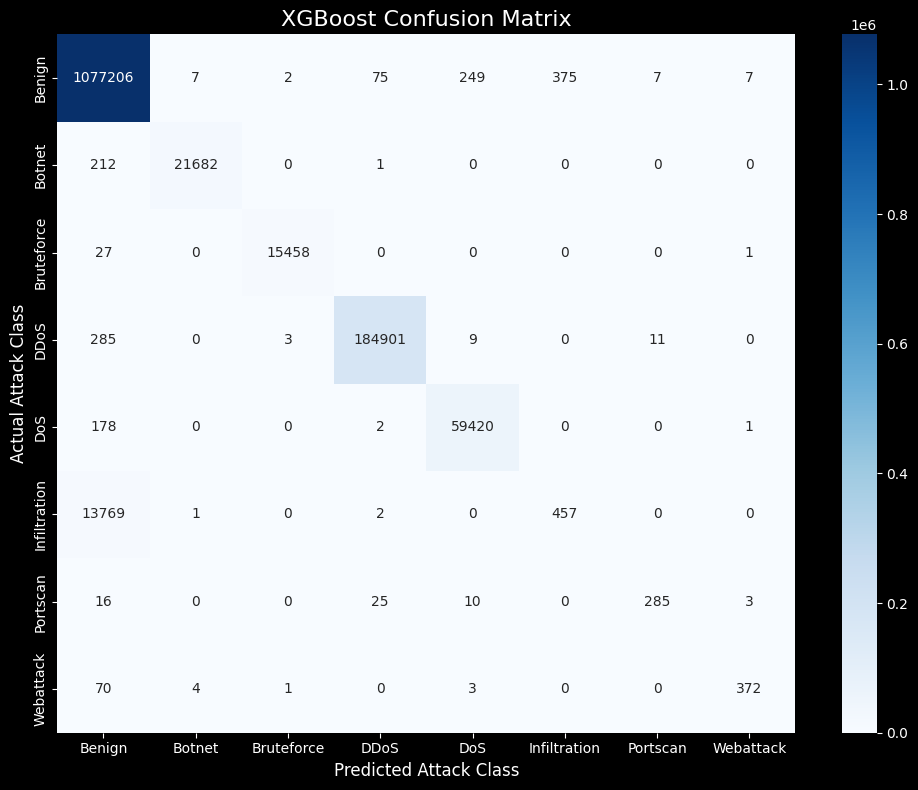

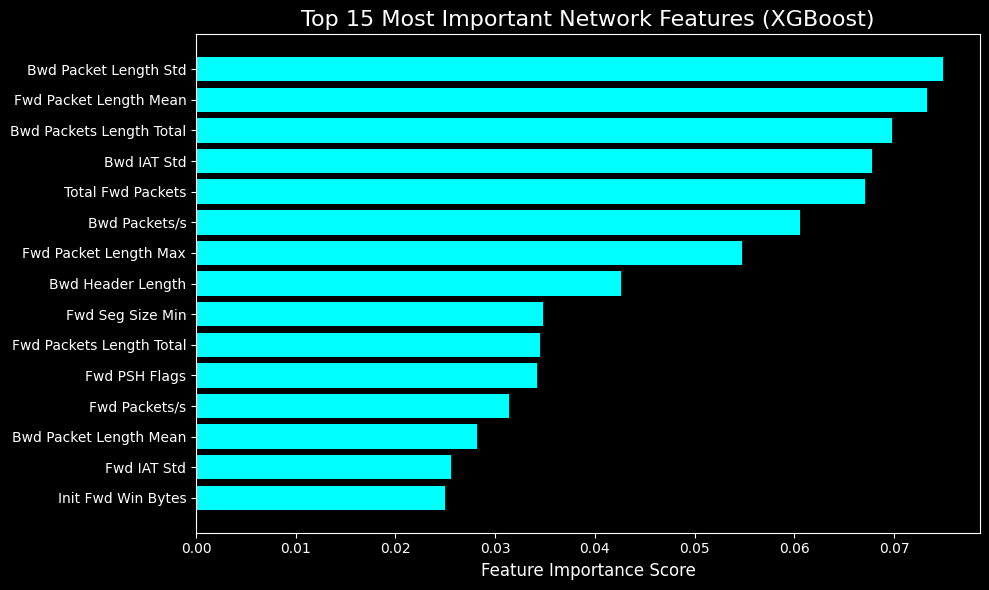

In [3]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

print("--- Training Tree Ensembles & Generating Visuals ---")

target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']

# 1. Random Forest
print("\nTraining Random Forest...")
rf_model = RandomForestClassifier(n_estimators=50, max_depth=15, class_weight='balanced', n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)

# 2. Scikit-Learn Gradient Boosting (Using the blazing-fast Hist variant)
print("Training Scikit-Learn Gradient Boosting...")
gb_model = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42)
gb_model.fit(X_train, y_train)

# 3. XGBoost
print("Training XGBoost...")
xgb_model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, tree_method='hist', n_jobs=-1, random_state=42)
xgb_model.fit(X_train, y_train)

# --- EVALUATION ---
models = {'Random Forest': rf_model, 'Gradient Boosting': gb_model, 'XGBoost': xgb_model}
best_model_name = "XGBoost" # We will visualize XGBoost by default

for name, model in models.items():
    print("\n" + "="*40)
    print(f" {name.upper()} (Validation Set) ")
    print("="*40)
    y_pred = model.predict(X_val)
    print(f"Accuracy:       {accuracy_score(y_val, y_pred):.4f}")
    print(f"Macro F1-Score: {f1_score(y_val, y_pred, average='macro'):.4f}")

    if name == best_model_name:
        xgb_preds = y_pred # Save for the confusion matrix

# --- VISUALIZATIONS FOR REPORT ---
plt.style.use('dark_background')

# Plot 1: Confusion Matrix (Proves where the model struggles)
fig, ax = plt.subplots(figsize=(10, 8))
cm = confusion_matrix(y_val, xgb_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names, ax=ax)
ax.set_title("XGBoost Confusion Matrix", fontsize=16)
ax.set_ylabel("Actual Attack Class", fontsize=12)
ax.set_xlabel("Predicted Attack Class", fontsize=12)
plt.tight_layout()
plt.show()

# Plot 2: Feature Importance (Shows what network features matter most)
fig, ax = plt.subplots(figsize=(10, 6))
# Get top 15 features from XGBoost
importances = xgb_model.feature_importances_
indices = np.argsort(importances)[-15:] # Top 15

ax.barh(range(len(indices)), importances[indices], align='center', color='cyan')
ax.set_yticks(range(len(indices)))
ax.set_yticklabels([X_train.columns[i] for i in indices])
ax.set_title("Top 15 Most Important Network Features (XGBoost)", fontsize=16)
ax.set_xlabel("Feature Importance Score", fontsize=12)
plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import classification_report

print("--- DETAILED CLASSIFICATION REPORTS (8 CLASSES) ---")
target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']

# Assuming models are still in memory as rf_model, gb_model, and xgb_model
models = {
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model,
    'XGBoost': xgb_model
}

for name, model in models.items():
    print("\n" + "="*55)
    print(f" {name.upper()} - FULL CLASSIFICATION REPORT ")
    print("="*55)

    # Predict on the unscaled validation set
    y_pred = model.predict(X_val)

    # Print the detailed per-class report
    print(classification_report(y_val, y_pred, target_names=target_names))

--- DETAILED CLASSIFICATION REPORTS (8 CLASSES) ---

 RANDOM FOREST - FULL CLASSIFICATION REPORT 
              precision    recall  f1-score   support

      Benign       1.00      0.71      0.83   1077928
      Botnet       0.96      1.00      0.98     21895
  Bruteforce       1.00      1.00      1.00     15486
        DDoS       0.98      1.00      0.99    185209
         DoS       0.96      1.00      0.98     59601
Infiltration       0.04      0.88      0.08     14229
    Portscan       0.66      0.90      0.76       339
   Webattack       0.06      0.90      0.11       450

    accuracy                           0.77   1375137
   macro avg       0.71      0.92      0.72   1375137
weighted avg       0.98      0.77      0.85   1375137


 GRADIENT BOOSTING - FULL CLASSIFICATION REPORT 
              precision    recall  f1-score   support

      Benign       0.99      1.00      0.99   1077928
      Botnet       1.00      0.99      0.99     21895
  Bruteforce       1.00      1.00     

Generating Per-Class F1-Score Comparison Plot...


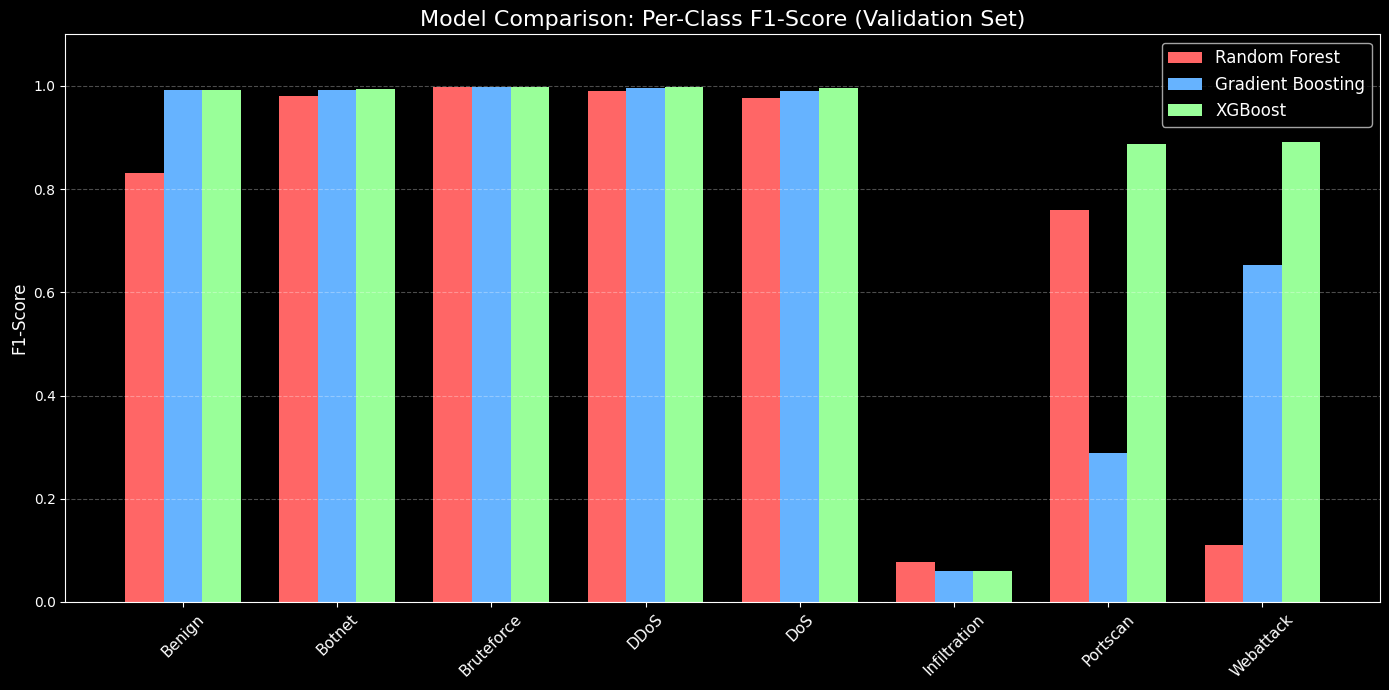

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score

print("Generating Per-Class F1-Score Comparison Plot...")

# 1. Get predictions (this is very fast for trees)
y_pred_rf = rf_model.predict(X_val)
y_pred_gb = gb_model.predict(X_val)
y_pred_xgb = xgb_model.predict(X_val)

# 2. Calculate per-class F1-scores (average=None returns an array of scores for all 8 classes)
f1_rf = f1_score(y_val, y_pred_rf, average=None)
f1_gb = f1_score(y_val, y_pred_gb, average=None)
f1_xgb = f1_score(y_val, y_pred_xgb, average=None)

# 3. Plotting Setup
target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']
x = np.arange(len(target_names))
width = 0.25  # Width of the bars

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(14, 7))

# 4. Create the grouped bars
ax.bar(x - width, f1_rf, width, label='Random Forest', color='#ff6666')
ax.bar(x, f1_gb, width, label='Gradient Boosting', color='#66b3ff')
ax.bar(x + width, f1_xgb, width, label='XGBoost', color='#99ff99')

# 5. Formatting
ax.set_ylabel('F1-Score', fontsize=12)
ax.set_title('Model Comparison: Per-Class F1-Score (Validation Set)', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(target_names, rotation=45, fontsize=11)
ax.legend(fontsize=12)
ax.set_ylim([0.0, 1.1])
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# MLP Pipeline

In [5]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import classification_report, accuracy_score, f1_score
import time

print("Building Scaler and Enhanced MLP...")
#Three layer deep funnel (128->64->32) to capture complex non-linear attacks
mlp_pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),
        batch_size=2048,           # CRITICAL: Processes data in larger chunks, drastically cutting train time
        max_iter=200,              # Increased ceiling for epochs to ensure convergence
        early_stopping=True,       # Prevents overfitting and endless training
        n_iter_no_change=10,       # Waits for 10 epochs of no improvement before stopping
        learning_rate_init=0.001,  # Slower, more precise learning rate (the default)
        random_state=42
    ))
])

print("Training Enhanced MLP...")
start_time = time.time()
mlp_pipeline.fit(X_train, y_train)
print(f"MLP trained in {time.time() - start_time:.1f} seconds.")

print("\n" + "="*50)
print(" ENHANCED MLP PERFORMANCE (Validation Set) ")
print("="*50)
y_val_pred_mlp = mlp_pipeline.predict(X_val)
print(f"Accuracy:       {accuracy_score(y_val, y_val_pred_mlp):.4f}")
print(f"Macro F1-Score: {f1_score(y_val, y_val_pred_mlp, average='macro'):.4f}")
print("\nMLP Classification Report:")
print(classification_report(y_val, y_val_pred_mlp, target_names=target_names))

Building Scaler and Enhanced MLP...
Training Enhanced MLP...
MLP trained in 173.5 seconds.

 ENHANCED MLP PERFORMANCE (Validation Set) 
Accuracy:       0.9231
Macro F1-Score: 0.5613

MLP Classification Report:
              precision    recall  f1-score   support

      Benign       0.93      0.98      0.95   1077928
      Botnet       0.99      0.97      0.98     21895
  Bruteforce       1.00      0.97      0.99     15486
        DDoS       0.98      0.67      0.80    185209
         DoS       0.72      0.83      0.77     59601
Infiltration       0.00      0.00      0.00     14229
    Portscan       0.00      0.00      0.00       339
   Webattack       0.00      0.00      0.00       450

    accuracy                           0.92   1375137
   macro avg       0.58      0.55      0.56   1375137
weighted avg       0.92      0.92      0.92   1375137



# Testing and Evaluation

Loading Unseen Test Set from Checkpoint...
Calculating Probabilities for One-vs-Rest ROC-AUC...


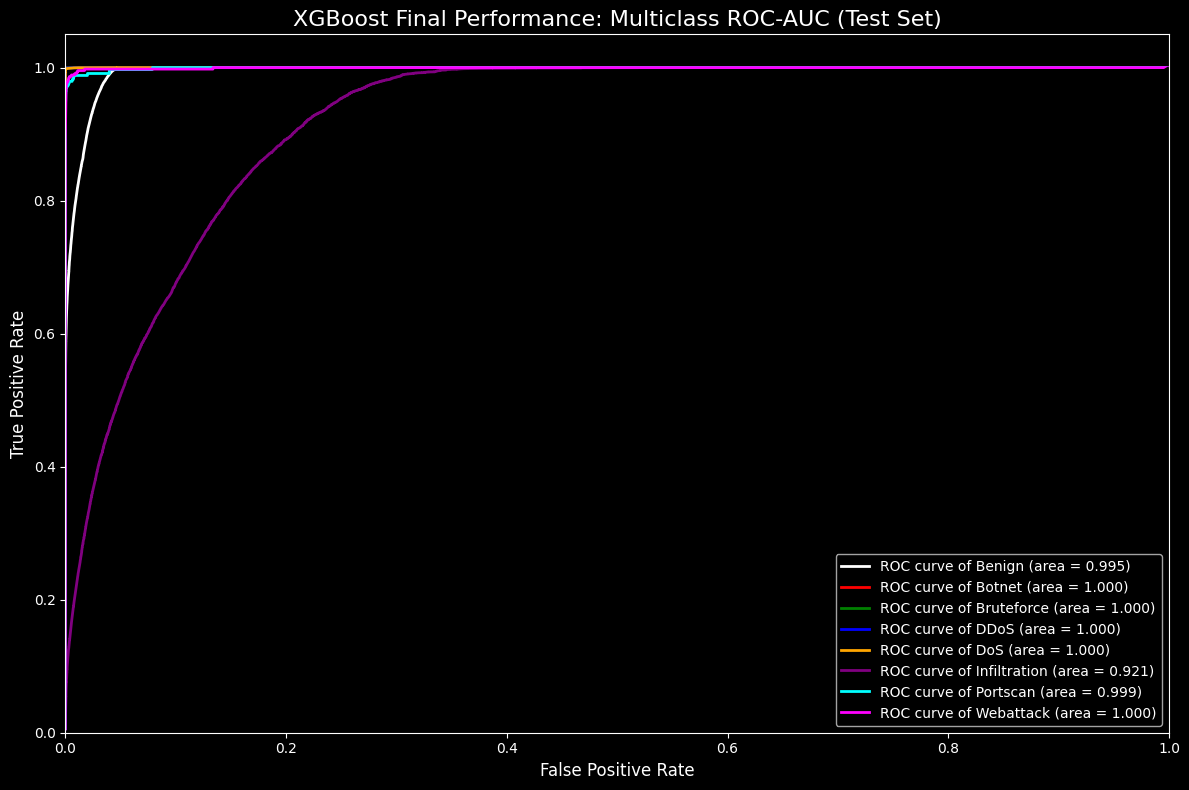

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

print("Loading Unseen Test Set from Checkpoint...")
test = pd.read_parquet('test_clean.parquet')
X_test = test.drop(columns=['Target'])
y_test = test['Target']

target_names = ['Benign', 'Botnet', 'Bruteforce', 'DDoS', 'DoS', 'Infiltration', 'Portscan', 'Webattack']
n_classes = len(target_names)

print("Calculating Probabilities for One-vs-Rest ROC-AUC...")
# 1. Binarize the labels for OvR
y_test_bin = label_binarize(y_test, classes=range(n_classes))

# 2. Get prediction probabilities from the XGBoost model
y_score = xgb_model.predict_proba(X_test)

# 3. Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 4. Plot all ROC curves
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(12, 8))
colors = ['white', 'red', 'green', 'blue', 'orange', 'purple', 'cyan', 'magenta']

for i, color in zip(range(n_classes), colors):
    ax.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve of {target_names[i]} (area = {roc_auc[i]:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=2) # Diagonal guessing line
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('XGBoost Final Performance: Multiclass ROC-AUC (Test Set)', fontsize=16)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Precision-Recall Curve and Log Scale Distribution Plot

Generating Final Visuals: PR-Curve and Class Distribution...


/tmp/ipykernel_5449/803663679.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.values, y=[target_names[i] for i in class_counts.index],


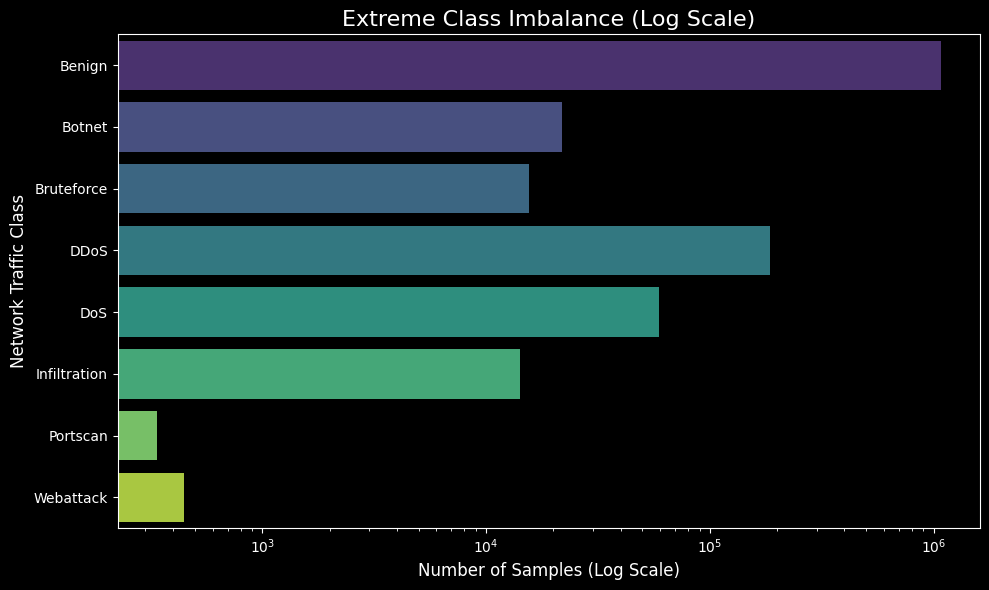

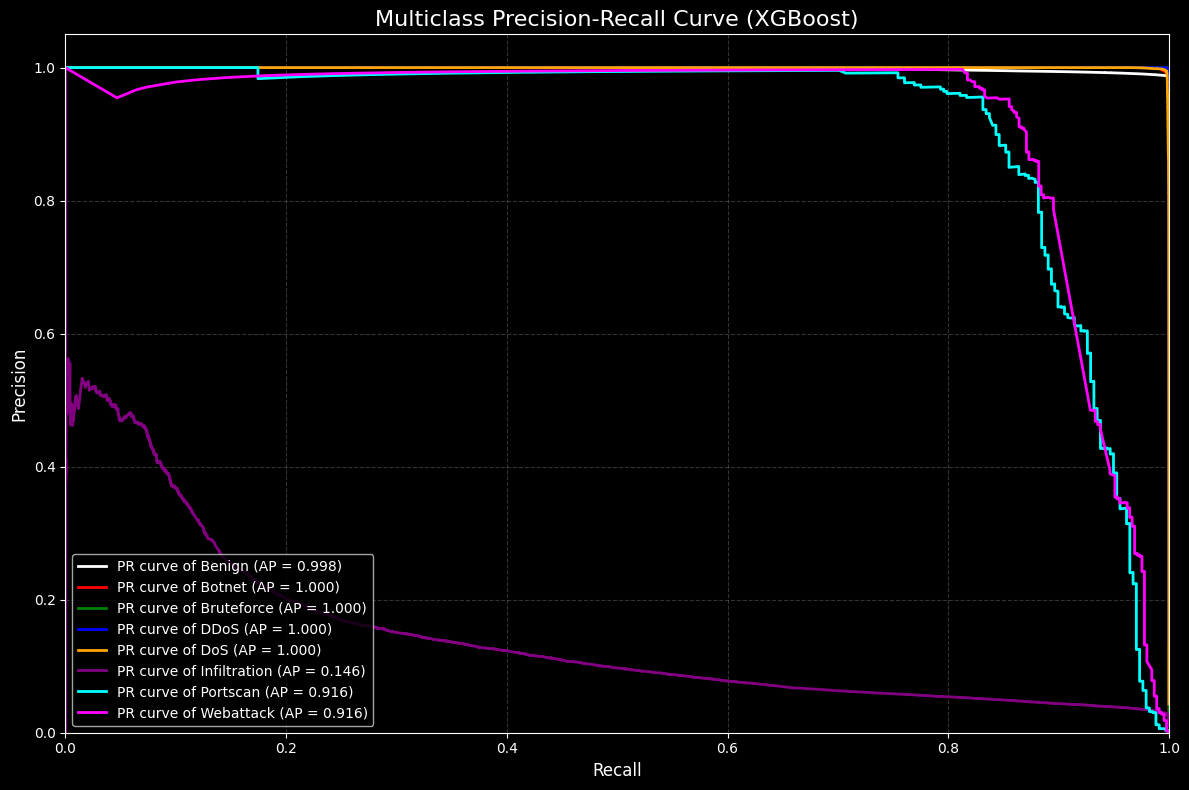

In [10]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import seaborn as sns

print("Generating Final Visuals: PR-Curve and Class Distribution...")

# 1. Log-Scale Class Distribution (Proves the extreme imbalance)
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10, 6))
# Count occurrences in the test set
class_counts = y_test.value_counts().sort_index()

# Bar plot with a logarithmic scale so the 450 Webattacks are visible next to 1M Benign
sns.barplot(x=class_counts.values, y=[target_names[i] for i in class_counts.index],
            palette='viridis', ax=ax)
ax.set_xscale('log')
ax.set_title('Extreme Class Imbalance (Log Scale)', fontsize=16)
ax.set_xlabel('Number of Samples (Log Scale)', fontsize=12)
ax.set_ylabel('Network Traffic Class', fontsize=12)
plt.tight_layout()
plt.show()

# 2. Multiclass Precision-Recall Curve (The gold standard for imbalanced data)
precision = dict()
recall = dict()
average_precision = dict()

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    average_precision[i] = average_precision_score(y_test_bin[:, i], y_score[:, i])

fig, ax = plt.subplots(figsize=(12, 8))
colors = ['white', 'red', 'green', 'blue', 'orange', 'purple', 'cyan', 'magenta']

for i, color in zip(range(n_classes), colors):
    ax.plot(recall[i], precision[i], color=color, lw=2,
             label=f'PR curve of {target_names[i]} (AP = {average_precision[i]:.3f})')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Multiclass Precision-Recall Curve (XGBoost)', fontsize=16)
ax.legend(loc="lower left")
plt.grid(alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()